In [ ]:
import pandas as pd
url = "https://raw.githubusercontent.com/yuvraj56j-del/Digital-wallet-payment-and-consumer-choice-project/main/data/raw/digital_payment_transactions_dirty.xlsx"
df = pd.read_excel(url)
df_clean = df.copy()

def summarize_missingness(data):
    """Return null count and percentage for each column, largest first."""
    out = pd.DataFrame({
        "null_count": data.isna().sum(),
        "null_percent": (data.isna().mean() * 100).round(2),
    })
    return out.sort_values("null_count", ascending=False)

def summarize_categories(data, column):
    """Return every distinct label in a column with its count (shows spelling variants)."""
    return data[column].value_counts(dropna=False).rename_axis(column).reset_index(name="count")


In [2]:
import pandas as pd

url = "https://raw.githubusercontent.com/yuvraj56j-del/Digital-wallet-payment-and-consumer-choice-project/main/data/processed/digital_payment_transactions_cleaned.csv"

df_clean = pd.read_csv(url)

print(df_clean.head())

   transaction_id            timestamp    merchant_category    amount  \
0  TXN20250016413  2025-05-13 12:18:54        Cash Transfer  11070.29   
1  TXN20250006473  2025-01-29 11:29:05  Government Services   3566.50   
2  TXN20250004783  2025-11-28 04:54:27             Shopping   4166.72   
3  TXN20250009321  2025-12-05 14:13:05        Food & Dining    665.10   
4  TXN20250006513  2025-09-09 08:58:53               Travel   2794.76   

  currency    payment_channel      customer_segment   region  \
0      KES      Mobile Wallet     Salaried Employee  Nairobi   
1      KES         QR Payment     Salaried Employee   Kiambu   
2      KES  NFC / Contactless     Salaried Employee  Nairobi   
3      KES     In-App Payment  Small Business Owner  Eldoret   
4      KES         QR Payment               Student  Nairobi   

  transaction_status day_of_week  id_repeated  non_kes  amount_invalid  \
0         Successful     Tuesday        False    False           False   
1         Successful   Wedne

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.5 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.5 MB 1.4 MB/s eta 0:00:07
   -- ------------------------------------- 0.5/9.5 MB 1.4 MB/s eta 0:00:07
   -- ------------------------------------- 0.5/9.5 MB 1.4 MB/s eta 0:00:07
   --- ------------------------------------ 0.8/9.5 MB 649.3 kB/s eta 0:00:14
   ------ --------------------------------- 1.6/9.5 MB 1.1 MB/s eta 0:00:08
   ------- -------------------------------- 1.8/9.5 MB 903.5 kB/s eta 0:00:09
   --------- ------------------------------ 2.4/9.5 MB 1.1 MB/s eta 0:00:07
   ----------- ---------------------------- 2.6/9.5 MB 1.1 MB/s eta 0:00:07
   ------------ --------------------------- 2.9/9.5 MB 1.1 MB/s eta 0:00:07
   -------------- ------------------------- 3.4/9.5 MB 1.1 MB/s eta 0:00:06
   --------------- ------------------------ 3.7/9.5 MB 1.1 MB/s eta 0:00:06
   ---------------- -------

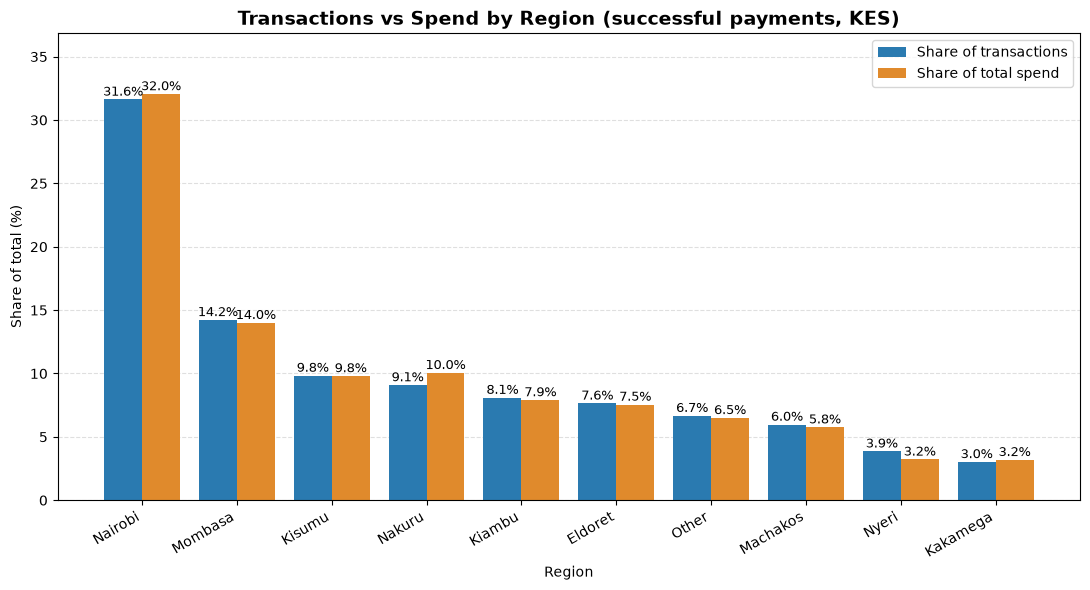

,transactions,total_spend,share_of_transactions_%,share_of_spend_%
region,,,,
Nairobi,5120,10224185.9,31.6,32.0
Mombasa,2304,4465412.4,14.2,14.0
Kisumu,1592,3126389.6,9.8,9.8
Nakuru,1471,3206041.0,9.1,10.0
Kiambu,1310,2520963.3,8.1,7.9
Eldoret,1237,2407951.7,7.6,7.5
Other,1079,2071283.3,6.7,6.5
Machakos,967,1836337.8,6.0,5.8
Nyeri,624,1026635.4,3.9,3.2


In [4]:
%pip install matplotlib
import matplotlib.pyplot as plt
import numpy as np

# Successful payments with a usable KES amount (the rows used for spending analysis)
spending = df_clean[
    (df_clean["transaction_status"] == "Successful")
    & df_clean["amount"].notna()
    & ~df_clean["amount_invalid"]
    & ~df_clean["is_outlier"]
    & (df_clean["currency"] == "KES")
    & (df_clean["region"] != "Unknown")
]

# For each region: number of transactions and total spend, each as a % of the overall total
by_region = spending.groupby("region")["amount"].agg(transactions="count", total_spend="sum")
by_region["share_of_transactions_%"] = by_region["transactions"] / by_region["transactions"].sum() * 100
by_region["share_of_spend_%"] = by_region["total_spend"] / by_region["total_spend"].sum() * 100
by_region = by_region.sort_values("share_of_transactions_%", ascending=False)

# Draw two bars side by side for each region
x = np.arange(len(by_region))
width = 0.4

fig, ax = plt.subplots(figsize=(11, 6))
bars1 = ax.bar(x - width / 2, by_region["share_of_transactions_%"], width,
               label="Share of transactions", color="#2a7ab0")
bars2 = ax.bar(x + width / 2, by_region["share_of_spend_%"], width,
               label="Share of total spend", color="#e08a2c")

# Write the percentage on top of each bar
for bars in (bars1, bars2):
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.3,
                f"{bar.get_height():.1f}%", ha="center", fontsize=9)

ax.set_title("Transactions vs Spend by Region (successful payments, KES)", fontsize=14, fontweight="bold")
ax.set_xlabel("Region")
ax.set_ylabel("Share of total (%)")
ax.set_xticks(x)
ax.set_xticklabels(by_region.index, rotation=30, ha="right")
ax.set_ylim(0, by_region[["share_of_transactions_%", "share_of_spend_%"]].max().max() * 1.15)
ax.legend()
ax.grid(axis="y", linestyle="--", alpha=0.4)
ax.set_axisbelow(True)

plt.tight_layout()
plt.savefig("transactions_vs_spend_by_region.png", dpi=150)
plt.show()
by_region.round(1)

## Interpretation

The results show that, for most regions, the percentage of total transactions is very similar to the percentage of total spending. This suggests that regions with more transactions also tend to contribute a similar share of overall spending.

For example, **Nairobi** accounted for **31.6% of all transactions** and **32.0% of total spending**, while **Kisumu** contributed **9.8% of transactions** and **9.8% of spending**. This close match indicates that transaction activity and spending are largely balanced across these regions.

A few regions showed small differences. **Nakuru** generated **9.1% of transactions** but contributed a slightly higher **10.0% of total spending**, while **Nyeri** accounted for **3.9% of transactions** but only **3.2% of spending**.

Overall, the findings suggest that regional differences are mainly driven by the **number of transactions being made rather than the value of individual transactions**. In other words, regions that contribute more spending generally do so because they process more transactions, not because their transactions are significantly larger.

### Limitation

This chart shows the percentage share of transactions and spending by region, but it does not show the actual number of transactions or the total amount spent. As a result, regions with similar percentages may still differ significantly in their actual transaction volumes and spending values.

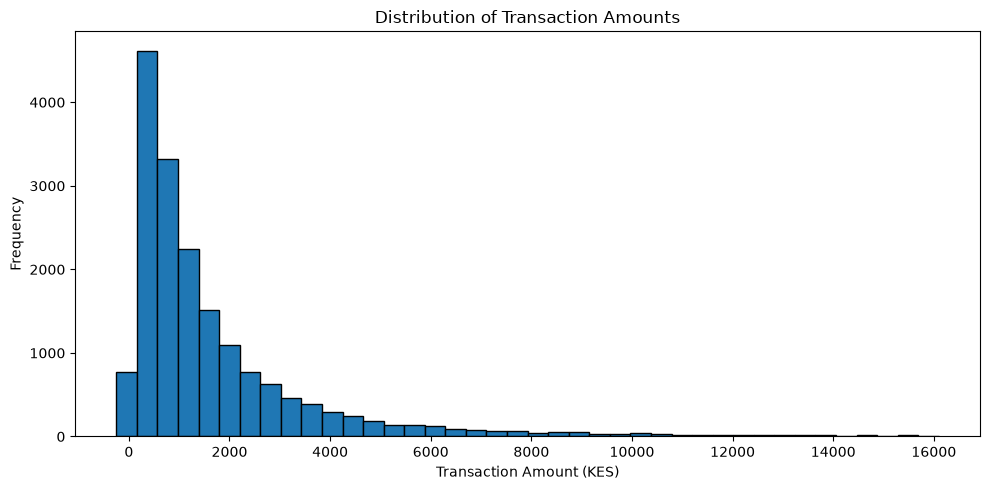

In [6]:
import matplotlib.pyplot as plt

# Keep only the lower 99% of transaction amounts
amounts = df_clean[df_clean["amount"] <= df_clean["amount"].quantile(0.99)]["amount"]

plt.figure(figsize=(10, 5))
plt.hist(amounts, bins=40, edgecolor="black")

plt.title("Distribution of Transaction Amounts")
plt.xlabel("Transaction Amount (KES)")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Interpretation

The histogram shows that most transaction amounts are relatively small, with the highest concentration of transactions occurring below **2,000 KES**. The most common transaction amounts appear to fall between **500 KES and 1,500 KES**.

As the transaction amount increases, the number of transactions decreases steadily. This creates a **right-skewed distribution**, where a large number of small transactions are accompanied by a smaller number of high-value transactions.

There is also a long tail extending to approximately **16,000 KES**, indicating that a few transactions involved much larger amounts. However, these high-value transactions are relatively uncommon compared to the majority of transactions.

Overall, the distribution suggests that customers typically make **low- to medium-value transactions**, while large transactions occur much less frequently.

### Limitation

A limitation of this histogram is that it shows the overall distribution of transaction amounts, but it does not explain why the amounts vary. For example, it does not show differences between regions, payment channels, customer segments, or transaction statuses that may influence the distribution.

Therefore, while the histogram is useful for understanding the spread of transaction amounts, it cannot identify the factors contributing to the observed pattern.

### Why a Horizontal Bar Chart Instead of a Pie Chart?

A horizontal bar chart was used because it makes it easier to compare the spending shares of different merchant categories. Small differences between categories can be seen more clearly using bar lengths, whereas pie chart slices can be difficult to compare accurately, especially when there are many categories with similar percentages.

### Limitation

Although the chart shows the share of spending by each merchant category, it does not show the actual amount spent or the number of transactions in each category. As a result, categories with similar spending shares may still differ significantly in their transaction volumes.

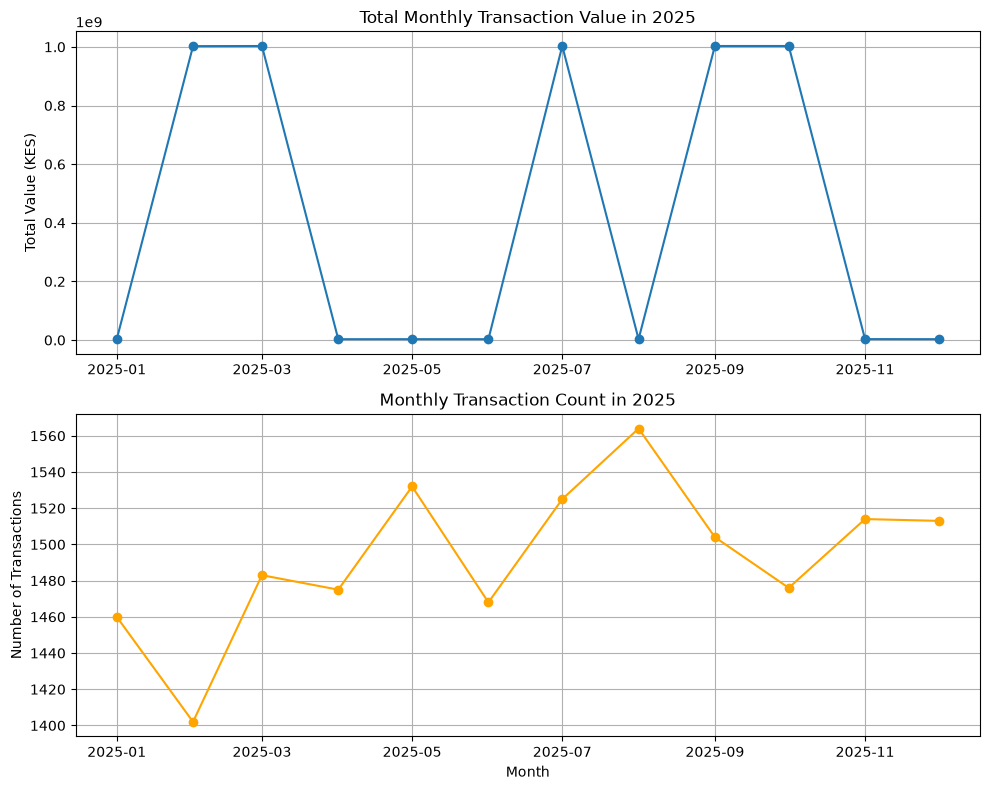

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

# Convert timestamp to datetime
df_clean["timestamp"] = pd.to_datetime(df_clean["timestamp"])

# Filter for 2025
df_2025 = df_clean[df_clean["timestamp"].dt.year == 2025]

# Monthly transaction value
monthly_value = (
    df_2025.groupby(df_2025["timestamp"].dt.to_period("M"))["amount"]
    .sum()
)

# Monthly transaction count
monthly_count = (
    df_2025.groupby(df_2025["timestamp"].dt.to_period("M"))["transaction_id"]
    .count()
)

# Convert period index to timestamp for plotting
monthly_value.index = monthly_value.index.to_timestamp()
monthly_count.index = monthly_count.index.to_timestamp()

# Create two line charts
fig, axes = plt.subplots(2, 1, figsize=(10, 8))

# Chart 1: Monthly transaction value
axes[0].plot(monthly_value.index, monthly_value.values, marker="o")
axes[0].set_title("Total Monthly Transaction Value in 2025")
axes[0].set_ylabel("Total Value (KES)")
axes[0].grid(True)

# Chart 2: Monthly transaction count
axes[1].plot(monthly_count.index, monthly_count.values, marker="o", color="orange")
axes[1].set_title("Monthly Transaction Count in 2025")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Number of Transactions")
axes[1].grid(True)

plt.tight_layout()
plt.show()

## Interpretation

The monthly transaction count remained relatively stable throughout 2025, ranging from approximately **1,400 to 1,560 transactions per month**. Transaction activity was lowest in **February** and highest in **August**, but the differences between months were fairly small. This suggests that transaction volume was generally consistent throughout the year, with no strong seasonal patterns.

However, the monthly transaction value chart shows unusual fluctuations, with several months reaching approximately **1 billion KES** while others are close to zero. Given that transaction counts remain stable across all months, these sharp changes in total value are unlikely to reflect normal spending behavior.

This pattern suggests that the monthly transaction value may be heavily influenced by one or more extremely large transactions (outliers) present in the dataset. Therefore, the value trend should be interpreted with caution, as it may not accurately represent typical customer spending during the year.

Overall, the transaction count indicates a steady level of activity throughout 2025, while the transaction value chart appears to be distorted by unusually large transaction amounts.

A limitation of these line charts is that extreme transaction values can significantly influence the monthly total spending trend. As a result, the chart may overstate changes in spending and may not accurately reflect the typical transaction behavior of most customers.